In [1]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [2]:
def treatState(state,pos_space,vel_space,ang_space,ang_vel_space):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [3]:
class IncrQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.increasing_reward(self.goal - abs(self.goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result) ))"""

In [4]:
class DecrQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=(self.goal - abs(self.goal-result))/self.goal
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],(goal - abs(goal-result))/goal)
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],(goal - abs(goal-result))/goal)"""

In [5]:
class STDQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.std=20
        self.goal=goal
        
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        if result < self.goal-self.std:
            reward=1
        elif result > self.goal+self.std:
            reward=-1
        else:
            reward=self.goal - abs(self.goal-result)
        for i in range(len(episodes)-1,-1,-1):
            """if i < goal-10:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],1)
                continue
            if i > goal+10:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],-1)
                continue"""
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma

In [6]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.goal - abs(self.goal-result)
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma

In [7]:
class expQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal,p=2):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        self.p=p
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        k=0.01
        p=self.p
        if value < 0:
            return - abs((((1+k*value)**p)-1)/p)
        return (((1+k*value)**p)-1)/p
    
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.increasing_reward(self.goal - abs(self.goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result) ))"""

In [8]:
def uniTraining(goal,episodeNumber=30000,type="inc",p=2):
    timeSteps=10000
    episodesResults=[]
    episodesTestResults=[]
    episodesTestResultsDeviation=[]
    numberOfTest=50
    if type == "inc":
        qagent= IncrQlearning(0.1,0.99,0.1,2,goal)
    elif type == "dec":
        qagent= DecrQlearning(0.1,0.99,0.1,2,goal)
    elif type == "std":
        qagent= STDQlearning(0.1,0.99,0.1,2,goal)
    elif type == "base":
        qagent= Qlearning(0.1,0.99,0.1,2,goal)
    elif type == "exp":
        qagent= expQlearning(0.1,0.99,0.1,2,goal,p)
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)

    for episodeIndex in range(episodeNumber):
       
        state,_=env.reset()
        state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
        #print("episode: ",episodeIndex)
        episodeObservation=[]
        for timeIndex in range(timeSteps):
            action=qagent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
            episodeObservation.append([tuple(state),action,tuple(next_state)])
            #qagent.update(tuple(state),action,tuple(next_state),reward)
            state=next_state
            if (terminated):
                #print("Number of steps :",timeIndex)
                
                episodesResults.append(timeIndex)
                break
    
        qagent.episodeRewards(episodeObservation)
        if(episodeIndex %500 ==0):
            qagent.epsilon=0
            testResultList=[]
            for episodeIndex in range(numberOfTest):
        
                state,_=env.reset()
                state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
                for timeIndex in range(timeSteps):
                    action=qagent.getAction(tuple(state))
                    next_state, reward, terminated, truncated, info =env.step(action)
                    next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
                    state=next_state
                    if (terminated):
                        testResultList.append(timeIndex)
                        break
    
            episodesTestResults.append(sum(testResultList)/len(testResultList))
            episodesTestResultsDeviation.append(np.std(episodesTestResults))
            qagent.epsilon=0.1
        
    
    
    env.close() 
    return episodesResults,episodesTestResults,episodesTestResultsDeviation,qagent

In [9]:
def uniTest(agent,epsilon=0):
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)
    timeSteps=10000
    agent.epsilon=epsilon
    last1000testList=[]
    for episodeIndex in range(1000):
    
        state,_=env.reset()
        state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
        for timeIndex in range(timeSteps):
            action=agent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
            state=next_state
            if (terminated):
                last1000testList.append(timeIndex)
                break
    return np.mean(last1000testList),np.std(last1000testList)

In [10]:
distancetomeanAll=[]
for goal in range(60,170,10):
    distancetomean=[]
    for type in range(0,11):
        _,_,_,agent=uniTraining(goal,episodeNumber=10000,type="inc",p=3.5)
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/10)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std))
        distancetomean.append(abs(goal-np.mean(mean))/goal)
    distancetomeanAll.append(distancetomean)

60 89.2396 35.993720996722416
60 100.01489999999998 17.404133879804245
60 90.00070000000001 39.52555597898468
60 43.433800000000005 23.47067163924431
60 51.1503 30.200411414018816
60 39.4371 22.438536185217494
60 29.298499999999997 19.708707558313613
60 26.269799999999996 17.00106106223228
60 28.548099999999998 18.73964588019073
60 22.6748 13.436645041884102
60 21.2481 11.749613917355667
70 60.087700000000005 12.812219082006118
70 113.4147 32.45343589155799
70 82.9349 32.91564431650073
70 58.5472 29.097421431339956
70 54.3366 35.18481356543391
70 47.70830000000001 28.6173519860284
70 32.7275 25.117777991974968


KeyboardInterrupt: 

In [ ]:
avgstart=[]
for i in distancetomeanAll:
    plt.plot([x/10 for x in range(0,5)],i[:5])
    print(i[0:2])
    avgstart.append(i[0])
plt.legend([x for x in range(60,170,10)])
print(np.mean(avgstart))

In [ ]:
for i in [0,4,6]:
    plt.plot(distancetomeanAll[i])
plt.legend([0,4,6])

In [ ]:
distancetomeanAll2=[]
for type in ["inc"]:
    distancetomean=[]
    for goal in range(60,170,10):
        _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,0)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std))
        distancetomean.append(abs(goal-np.mean(mean))/goal)
    distancetomeanAll2.append(distancetomean)

In [ ]:
avgstart=[]
for i in distancetomeanAll2:
    plt.plot([x for x in range(60,170,10)],i)
    print(i[0:2])
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.savefig("SVG/MultiGoalIncreasedmean.svg")

In [15]:
distancetomeanAll3=[]
distancetoSTDAll3=[]
for goal in range(120,150,10):
    distancetomean=[]
    distancetostd=[]
    _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
    for type in range(0,101):
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/100)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std))
        distancetomean.append(np.mean(mean))
        distancetostd.append(np.mean(std))
    distancetomeanAll3.append(distancetomean)
    distancetoSTDAll3.append(distancetostd)

120 107.9048 6.278858114904419
120 107.44950000000001 7.092435318874429
120 106.91979999999998 8.176701434998277
120 106.4342 8.906893617818605
120 105.5069 10.758783917487865
120 105.12280000000001 11.36353702304231
120 104.2376 12.651507321464804
120 103.5039 13.644276886174657
120 102.6077 15.020509725587425
120 101.59539999999998 16.262360243411358
120 100.83420000000001 17.30217766597897
120 99.8692 18.23463180216852
120 98.6264 19.768786820258633
120 97.49549999999999 21.096910810938205
120 96.27349999999998 21.797470567206677
120 95.26079999999999 22.84641189595458
120 93.849 24.02674245365126
120 92.6036 25.20523455404032
120 91.14200000000001 25.978515951527193
120 89.6428 27.187576948422805
120 88.85589999999999 27.379238502484053
120 87.20509999999999 28.255702249912474
120 86.02329999999999 28.653745615883725
120 84.15330000000002 29.775063513417784
120 83.0472 30.091095140385825
120 81.3629 30.79272360854233
120 80.1138 31.238999151571868
120 77.8458 31.871533197890535
120

122.96819999999998


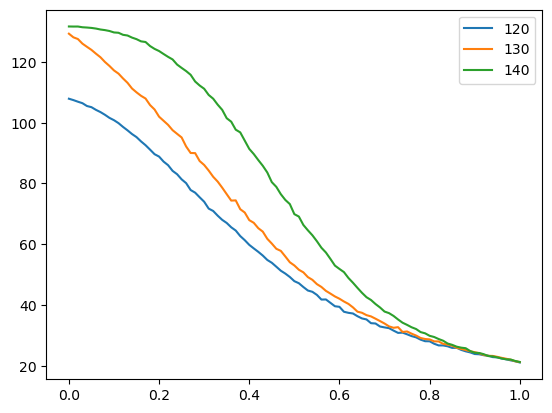

In [17]:
avgstart=[]
for i in distancetomeanAll3:
    plt.plot([x/100 for x in range(0,101)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(120,150,10)])
plt.savefig("SVG/MultiGoalIncreasedRand1.svg")

8.940593084585878


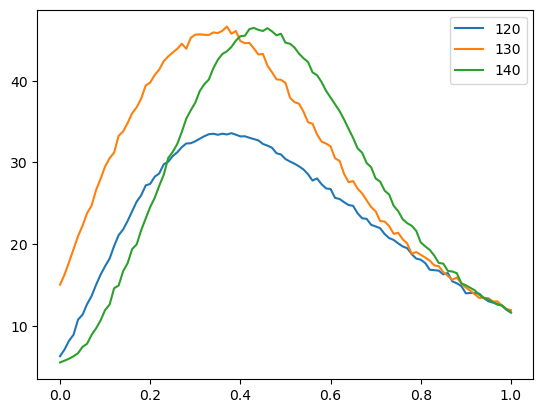

In [19]:
avgstart=[]
for i in distancetoSTDAll3:
    plt.plot([x/100 for x in range(0,101)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(120,150,10)])
plt.savefig("SVG/MultiGoalIncreasedRan2.svg")

In [29]:
distancetomeanAll3=[]
distancetoSTDAll3=[]
for goal in range(120,200,10):
    distancetomean=[]
    distancetostd=[]
    _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
    for type in range(0,101):
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/100)
            mean.append(testresult[0])
            std.append(testresult[1]) 
        print(goal,np.mean(mean),np.mean(std))
        if np.mean(mean) < 130 - 13 and len(distancetomean)>0 and distancetomean[-1]<130-13:
            break
        distancetomean.append(np.mean(mean))
        distancetostd.append(np.mean(std))
    distancetomeanAll3.append(distancetomean)
    distancetoSTDAll3.append(distancetostd)

120 114.32180000000001 5.032954700607139
120 114.09700000000001 5.762561711743048
130 125.98769999999999 6.215435013812455
130 125.4222 7.902365433639285
130 124.95259999999999 9.718216850266007
130 124.1354 11.502450855132595
130 123.402 13.203059408101513
130 122.88879999999999 14.300124167843856
130 122.3191 14.84732789938381
130 120.8895 17.676508484240767
130 120.44449999999999 18.392896945424006
130 119.18679999999999 20.345411567096637
130 118.0393 21.872793084602346
130 116.78839999999998 23.728004588260866
130 116.16580000000002 24.28517669148187
140 134.82560000000004 18.822580149418588
140 133.8337 20.179148320094704
140 132.65220000000002 21.75077514400353
140 132.2326 22.634740510029708
140 131.50830000000002 23.59408100769285
140 130.78339999999997 24.564814413994693
140 129.69830000000002 25.96739910017058
140 129.45319999999998 26.39963829021456
140 127.7897 28.33778667978005
140 127.35940000000001 28.880361607946373
140 126.32649999999998 30.227614058918874
140 125.273

135.23593333333335


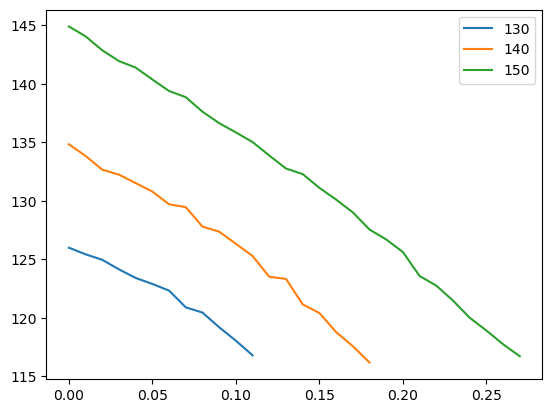

In [37]:
avgstart=[]
for i in distancetomeanAll3[1:-4]:
    plt.plot([x/100 for x in range(0,101)][:len(i)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(130,200,10)])
plt.savefig("SVG/MultiGoalIncreasedRan3.svg")

142.6982


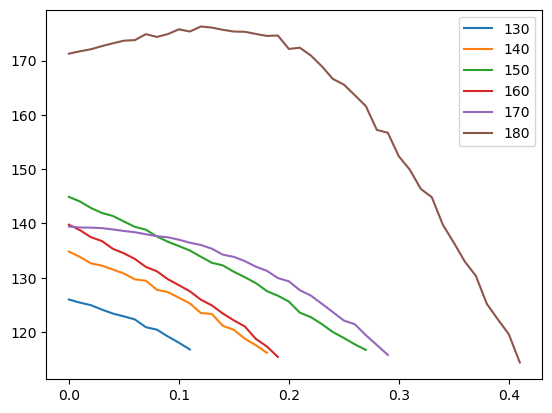

In [39]:
avgstart=[]
for i in distancetomeanAll3[1:-1]:
    plt.plot([x/100 for x in range(0,101)][:len(i)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(130,200,10)])
plt.savefig("SVG/MultiGoalIncreasedRan4.svg")

11.026680691767089


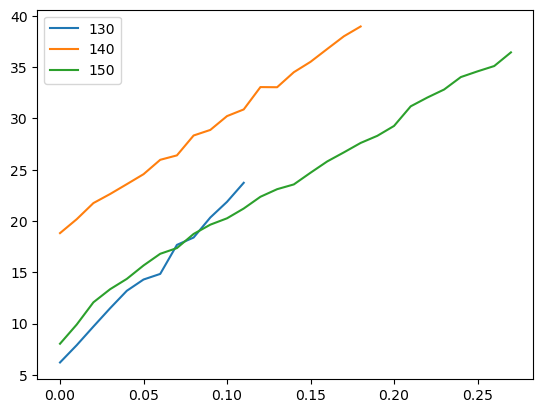

In [41]:
avgstart=[]
for i in distancetoSTDAll3[1:-4]:
    plt.plot([x/100 for x in range(0,101)][:len(i)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(130,200,10)])